# 04 — Decision Analysis: Calibration, Threshold/Cost, Interpretation, Test Evaluation

Goal: turn probabilities into an actionable retention policy, verify the
model is honest about its confidence, explain its decisions, and — **only
once, at the very end** — evaluate on the untouched test set.

> This notebook is the only place the test set is used, and only after the
> threshold has been frozen using validation data alone.


In [1]:
import sys
sys.path.insert(0, "..")

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import brier_score_loss

from src.data import TARGET_COLUMN, ID_COLUMN, get_feature_columns, RANDOM_SEED
from src.evaluate import (
    evaluate_at_threshold, threshold_search, find_optimal_threshold,
    cost_sensitivity_analysis, permutation_importance_report, shap_explanation,
    bootstrap_metric_ci, subgroup_metrics, risk_group, recommended_action,
    DEFAULT_FN_COST, DEFAULT_FP_COST,
)
from src.predict import ModelArtifact, generate_final_risk_report

train_df = pd.read_csv("../data/processed/train.csv")
val_df = pd.read_csv("../data/processed/val.csv")
test_df = pd.read_csv("../data/processed/test.csv")

numerical_columns, categorical_columns = get_feature_columns(train_df)
feature_cols = numerical_columns + categorical_columns

X_train, y_train = train_df[feature_cols], train_df[TARGET_COLUMN]
X_val, y_val = val_df[feature_cols], val_df[TARGET_COLUMN]
X_test, y_test = test_df[feature_cols], test_df[TARGET_COLUMN]

# Load the exact pipeline that `python -m src.train` selected and tuned instead
# of refitting a hand-picked model here. Refitting with hard-coded settings
# (the old behaviour) silently produced a second, slightly different "final"
# model, so notebook numbers drifted from models/model_metadata.json.
final_pipeline = joblib.load("../models/churn_pipeline.joblib")
model_metadata = joblib.load("../models/model_metadata.joblib")
print(f"Loaded model family: {model_metadata['model_family']}")
print(f"Frozen threshold from training run: {model_metadata['threshold']}")
val_proba = final_pipeline.predict_proba(X_val)[:, 1]
print(evaluate_at_threshold(y_val, val_proba))


Loaded model family: logistic_regression
Frozen threshold from training run: 0.05
ClassificationMetrics(threshold=0.5, accuracy=0.804162724692526, precision=0.6761904761904762, recall=0.505338078291815, f1=0.5784114052953157, roc_auc=0.8361338371794402, pr_auc=0.6405296733951744, brier=0.13816536965433593, tn=708, fp=68, fn=139, tp=142, prediction_latency_ms=0.0)


## 1. Calibration

A model can rank customers correctly (good ROC-AUC) while its raw
probabilities are poorly calibrated (e.g. everyone it calls "80% likely to
churn" actually churns only 50% of the time). Since we use probabilities
directly for cost calculations and risk-group thresholds, calibration
matters.


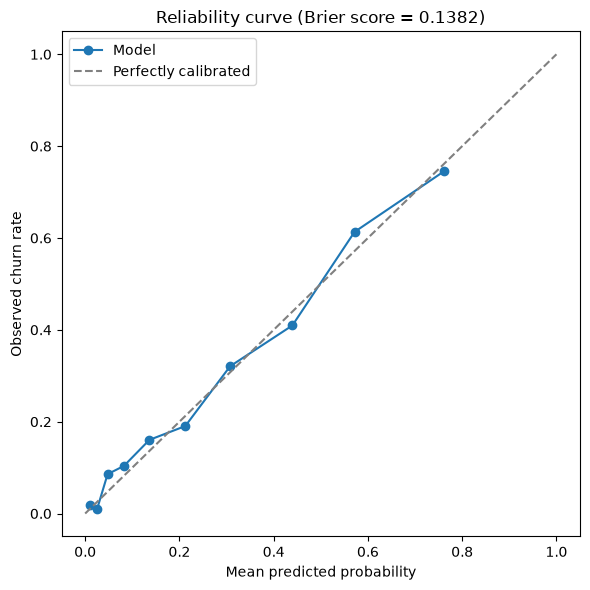

In [2]:
prob_true, prob_pred = calibration_curve(y_val, val_proba, n_bins=10, strategy="quantile")
brier = brier_score_loss(y_val, val_proba)

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(prob_pred, prob_true, marker="o", label="Model")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Perfectly calibrated")
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Observed churn rate")
ax.set_title(f"Reliability curve (Brier score = {brier:.4f})")
ax.legend()
plt.tight_layout()
plt.savefig("../reports/figures/calibration_curve.png", dpi=120)
plt.show()


In [3]:
calibrated = CalibratedClassifierCV(final_pipeline, method="isotonic", cv=5)
calibrated.fit(X_train, y_train)
calibrated_proba_val = calibrated.predict_proba(X_val)[:, 1]
print(f"Uncalibrated Brier: {brier:.4f}")
print(f"Isotonic-calibrated Brier: {brier_score_loss(y_val, calibrated_proba_val):.4f}")


Uncalibrated Brier: 0.1382
Isotonic-calibrated Brier: 0.1379


**Did calibration improve probability quality?** Compare the two Brier
scores above (lower is better). **Did it change threshold decisions?** Rerun
the threshold search (next section) on `calibrated_proba_val` instead of
`val_proba` and compare the resulting optimal threshold — a well-ranked but
poorly calibrated model can shift its cost-optimal threshold noticeably
after calibration even if ROC-AUC barely changes, because the *absolute*
probability values (not just their ranking) drive the cost calculation.


## 2. Threshold optimization by expected business cost

In [4]:
threshold_table = threshold_search(y_val, val_proba, fn_cost=DEFAULT_FN_COST, fp_cost=DEFAULT_FP_COST)
threshold_table.head(10)


,threshold,precision,recall,f1,tn,fp,fn,tp,expected_cost,cost_per_customer
0,0.05,0.348271,0.967972,0.512241,267,509,9,272,19770.0,18.703879
1,0.06,0.360107,0.957295,0.523346,298,478,12,269,20340.0,19.243141
2,0.08,0.383502,0.943060,0.545267,350,426,16,265,20780.0,19.659413
3,0.07,0.372549,0.946619,0.534673,328,448,15,266,20940.0,19.810785
4,0.09,0.391304,0.928826,0.550633,370,406,20,261,22180.0,20.983917
5,0.10,0.399691,0.921708,0.557589,387,389,22,259,22670.0,21.447493
6,0.11,0.410543,0.914591,0.566703,407,369,24,257,23070.0,21.825922
7,0.12,0.420701,0.896797,0.572727,429,347,29,252,24910.0,23.566698
8,0.13,0.423208,0.882562,0.572088,438,338,33,248,26640.0,25.203406
9,0.14,0.428076,0.879004,0.575758,446,330,34,247,26900.0,25.449385


2026-10-20 23:29:01,126 | INFO | Optimal threshold = 0.05 (expected cost = 19770.00)


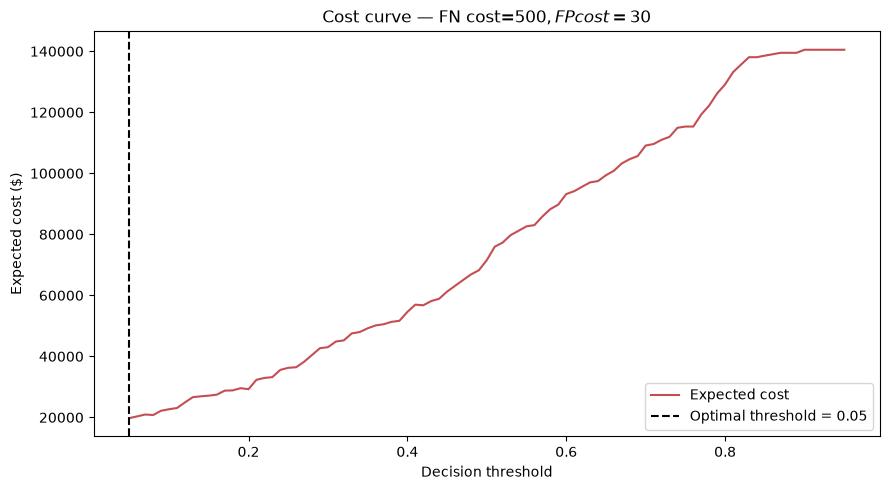

Frozen operating threshold: 0.05


In [5]:
optimal_threshold, _ = find_optimal_threshold(y_val, val_proba, fn_cost=DEFAULT_FN_COST, fp_cost=DEFAULT_FP_COST)

fig, ax1 = plt.subplots(figsize=(9, 5))
ax1.plot(threshold_table.sort_values("threshold")["threshold"],
          threshold_table.sort_values("threshold")["expected_cost"], color="#C44E52", label="Expected cost")
ax1.axvline(optimal_threshold, linestyle="--", color="black", label=f"Optimal threshold = {optimal_threshold:.2f}")
ax1.set_xlabel("Decision threshold")
ax1.set_ylabel("Expected cost ($)")
ax1.set_title(f"Cost curve — FN cost=${DEFAULT_FN_COST:.0f}, FP cost=${DEFAULT_FP_COST:.0f}")
ax1.legend()
plt.tight_layout()
plt.savefig("../reports/figures/cost_curve.png", dpi=120)
plt.show()

print(f"Frozen operating threshold: {optimal_threshold:.2f}")


**How sensitive is the threshold to the assumed cost ratio?** See the
sensitivity table below — the threshold moves substantially as the assumed
false-negative cost changes, which is exactly why we don't hard-code a
threshold assumption without stating it explicitly.


In [6]:
sensitivity_table = cost_sensitivity_analysis(y_val, val_proba, fn_costs=[200, 500, 1000, 2000])
sensitivity_table


2026-10-20 23:29:01,755 | INFO | Optimal threshold = 0.11 (expected cost = 15870.00)
2026-10-20 23:29:02,092 | INFO | Optimal threshold = 0.05 (expected cost = 19770.00)
2026-10-20 23:29:02,427 | INFO | Optimal threshold = 0.05 (expected cost = 24270.00)
2026-10-20 23:29:02,759 | INFO | Optimal threshold = 0.05 (expected cost = 33270.00)


,fn_cost_assumption,fp_cost_assumption,optimal_threshold,expected_cost,precision,recall
0,200,30.0,0.11,15870.0,0.410543,0.914591
1,500,30.0,0.05,19770.0,0.348271,0.967972
2,1000,30.0,0.05,24270.0,0.348271,0.967972
3,2000,30.0,0.05,33270.0,0.348271,0.967972


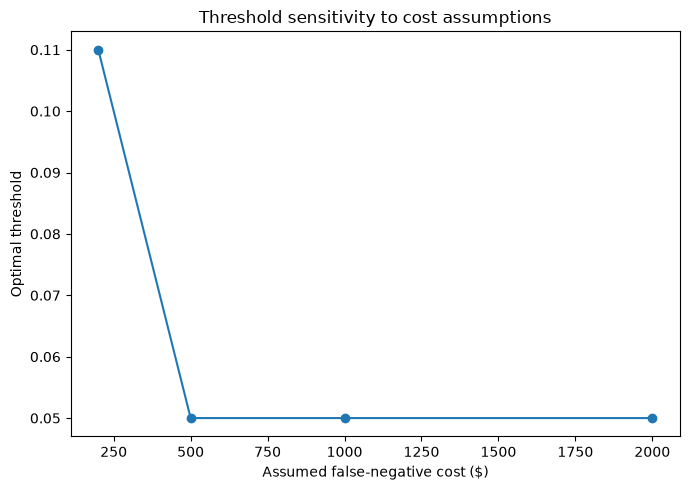

In [7]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(sensitivity_table["fn_cost_assumption"], sensitivity_table["optimal_threshold"], marker="o")
ax.set_xlabel("Assumed false-negative cost ($)")
ax.set_ylabel("Optimal threshold")
ax.set_title("Threshold sensitivity to cost assumptions")
plt.tight_layout()
plt.savefig("../reports/figures/threshold_sensitivity.png", dpi=120)
plt.show()


**Would different customer segments justify different thresholds?**
Plausibly yes — e.g. high-value long-tenure customers might warrant a lower
(more sensitive) threshold since a false negative is costlier in lost
lifetime value. Segment-specific thresholds could formalize this, but they
need minimum sample-size rules per segment and carry real fairness risk if
applied naively (e.g. systematically under-serving a demographic group), so
this is left as a deliberate extension, not a default.


## 3. Interpretation: permutation importance

In [8]:
perm_importance = permutation_importance_report(final_pipeline, X_val, y_val, n_repeats=10, random_state=RANDOM_SEED)
perm_importance.head(15)


,feature,importance_mean,importance_std
0,tenure,0.175460,0.011116
1,Contract,0.036597,0.004594
2,TotalCharges,0.025683,0.005064
3,InternetService,0.015147,0.003740
4,PaymentMethod,0.004596,0.001478
5,OnlineSecurity,0.003882,0.001178
6,TechSupport,0.003400,0.001902
7,PaperlessBilling,0.003329,0.002057
8,MultipleLines,0.002761,0.001295
9,StreamingTV,0.001479,0.000792


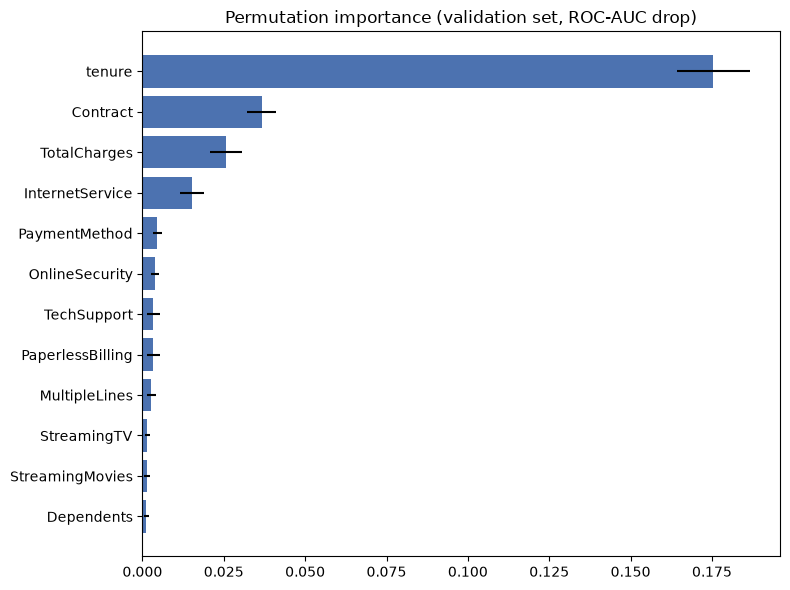

In [9]:
fig, ax = plt.subplots(figsize=(8, 6))
top = perm_importance.head(12).sort_values("importance_mean")
ax.barh(top["feature"], top["importance_mean"], xerr=top["importance_std"], color="#4C72B0")
ax.set_title("Permutation importance (validation set, ROC-AUC drop)")
plt.tight_layout()
plt.savefig("../reports/figures/permutation_importance.png", dpi=120)
plt.show()


## 4. SHAP explanations (falls back gracefully if `shap` is not installed)

2026-10-20 23:29:07,570 | WARNING | Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.


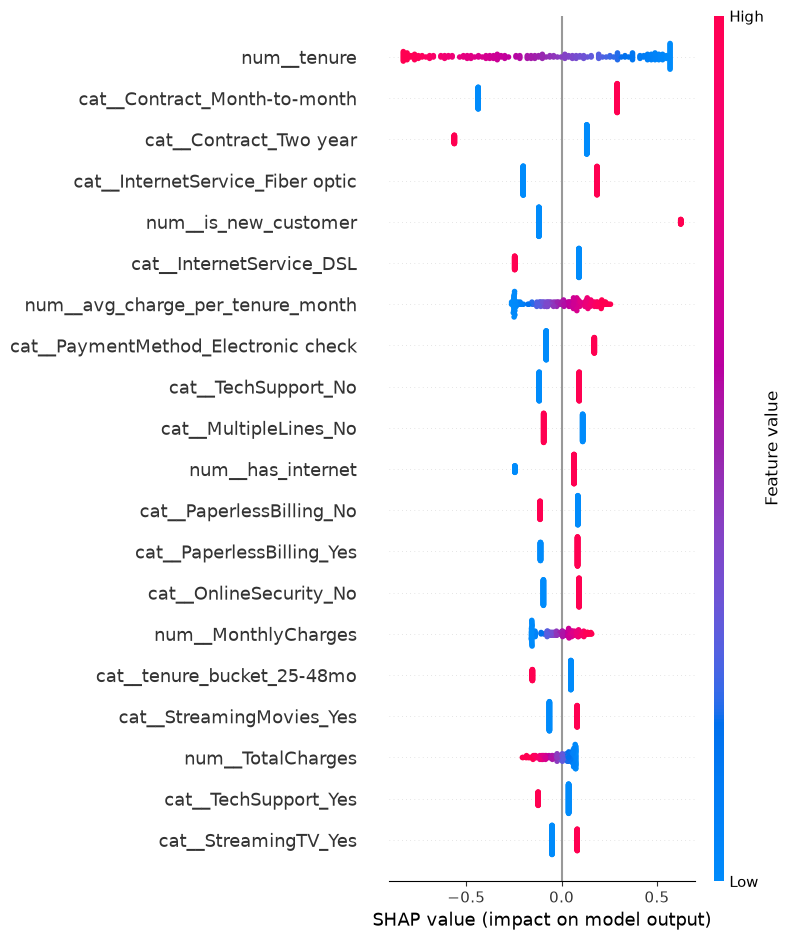

In [10]:
shap_values = shap_explanation(final_pipeline, X_val.sample(min(200, len(X_val)), random_state=RANDOM_SEED))
if shap_values is not None:
    import shap
    shap.summary_plot(shap_values, show=False)
    plt.tight_layout()
    plt.savefig("../reports/figures/shap_summary.png", dpi=120)
    plt.show()
else:
    print("SHAP not available in this environment — permutation importance above is the "
          "model-agnostic fallback. Install `pip install shap` for individual-prediction "
          "waterfall explanations.")


## 5. Individual explanations: true positives, false positives, false negatives

In [11]:
val_with_preds = val_df.copy()
val_with_preds["probability"] = val_proba
val_with_preds["prediction"] = (val_proba >= optimal_threshold).astype(int)

true_positives = val_with_preds[(val_with_preds[TARGET_COLUMN] == 1) & (val_with_preds["prediction"] == 1)]
false_positives = val_with_preds[(val_with_preds[TARGET_COLUMN] == 0) & (val_with_preds["prediction"] == 1)]
false_negatives = val_with_preds[(val_with_preds[TARGET_COLUMN] == 1) & (val_with_preds["prediction"] == 0)]

print("--- 3 True Positives (correctly flagged churners) ---")
print(true_positives[["customerID", "Contract", "tenure", "MonthlyCharges", "probability"]].head(3).to_string(index=False))

print("\n--- 3 False Positives (flagged but did not churn) ---")
print(false_positives[["customerID", "Contract", "tenure", "MonthlyCharges", "probability"]].head(3).to_string(index=False))

print("\n--- 3 False Negatives (missed churners) ---")
print(false_negatives[["customerID", "Contract", "tenure", "MonthlyCharges", "probability"]].head(3).to_string(index=False))


--- 3 True Positives (correctly flagged churners) ---
customerID       Contract  tenure  MonthlyCharges  probability
2657-ALMWY Month-to-month      26           84.95     0.407559
4248-HCETZ Month-to-month      30           79.65     0.337282
8992-JQYUN Month-to-month       1           50.35     0.801356

--- 3 False Positives (flagged but did not churn) ---
customerID       Contract  tenure  MonthlyCharges  probability
5600-KTXFM Month-to-month       2           69.95     0.572630
9943-VSZUV Month-to-month      67           75.70     0.277075
6408-OTUBZ       One year      66          104.55     0.090760

--- 3 False Negatives (missed churners) ---
customerID Contract  tenure  MonthlyCharges  probability
3400-ESFUW Two year      55           57.55     0.007707
0203-HHYIJ One year      25           25.30     0.035557
1725-IQNIY Two year      54          109.75     0.043499


**Which features consistently drive churn risk?** Cross-reference the
permutation-importance ranking with the coefficients from notebook 03 —
contract type, tenure, and internet/payment-method features should appear in
both. **Which explanations reveal model weakness rather than customer
behavior?** False negatives clustered among long-tenure customers with a
sudden late-life churn (a pattern the model under-weights because most
churn in training data is early-tenure) would indicate a genuine blind spot,
not just irreducible noise.


## 6. Reliability: subgroup metrics and bootstrap confidence intervals

In [12]:
val_with_preds["actual_churn"] = val_with_preds[TARGET_COLUMN]
sub_report = subgroup_metrics(
    val_with_preds, y_true_col=TARGET_COLUMN, y_pred_col="prediction",
    y_proba_col="probability", group_col="Contract", min_group_size=20,
)
sub_report


,group,n,reliable_sample_size,precision,recall,false_positive_rate,false_negative_rate,mean_predicted_probability,actual_churn_rate
0,Month-to-month,584,True,0.416235,1.000000,0.985423,0.000000,0.413555,0.412671
1,Two year,246,True,0.092308,0.545455,0.251064,0.454545,0.035664,0.044715
2,One year,227,True,0.182482,0.862069,0.565657,0.137931,0.106266,0.127753


In [13]:
point, lo, hi = bootstrap_metric_ci(y_val.values, val_proba, n_bootstrap=500, random_state=RANDOM_SEED)
print(f"ROC-AUC = {point:.4f}  (95% bootstrap CI: [{lo:.4f}, {hi:.4f}])")


ROC-AUC = 0.8361  (95% bootstrap CI: [0.8110, 0.8619])


Report metric differences relative to the width of this confidence
interval — e.g. a 0.01 ROC-AUC improvement from tuning is not meaningfully
different from zero if the CI half-width is 0.03.

## 7. Final evaluation — TEST SET, used exactly once


In [14]:
test_proba = final_pipeline.predict_proba(X_test)[:, 1]
test_metrics = evaluate_at_threshold(
    y_test, test_proba, threshold=optimal_threshold,
    measure_latency_model=final_pipeline, X_for_latency=X_test.iloc[:200],
)
print("FINAL TEST METRICS (frozen threshold, evaluated once):")
print(test_metrics)


FINAL TEST METRICS (frozen threshold, evaluated once):
ClassificationMetrics(threshold=0.05, accuracy=0.5288552507095553, precision=0.35917312661498707, recall=0.9928571428571429, f1=0.5275142314990512, roc_auc=0.8543597168597169, pr_auc=0.668867773425374, brier=0.13297826224492634, tn=281, fp=496, fn=2, tp=278, prediction_latency_ms=0.04372349998448044)


In [15]:
import json
with open("../reports/final_test_metrics.json", "w") as f:
    json.dump(test_metrics.as_dict(), f, indent=2)
print("Saved reports/final_test_metrics.json")


Saved reports/final_test_metrics.json


## 8. Final risk report — `predictions.csv`

In [16]:
artifact = ModelArtifact(
    pipeline=final_pipeline, threshold=optimal_threshold,
    model_version="logistic_regression-notebook-demo",
    trained_at=pd.Timestamp.now(tz="UTC").isoformat(),
    metrics_at_threshold=test_metrics.as_dict(),
)
risk_report = generate_final_risk_report(
    artifact, X_test, y_test.values, test_df[ID_COLUMN], output_path="../predictions.csv",
)
risk_report.head(10)


2026-10-20 23:29:09,517 | INFO | Final risk report written to ..\predictions.csv (1057 rows)


,customerID,actual_churn,probability,prediction,risk_group,recommended_action
0,5178-LMXOP,1,0.9111,1,High,Priority outreach: personal call + retention o...
1,1400-MMYXY,1,0.9064,1,High,Priority outreach: personal call + retention o...
2,6023-YEBUP,1,0.9020,1,High,Priority outreach: personal call + retention o...
3,0295-PPHDO,1,0.8952,1,High,Priority outreach: personal call + retention o...
4,9057-SIHCH,1,0.8949,1,High,Priority outreach: personal call + retention o...
5,2545-EBUPK,0,0.8883,1,High,Priority outreach: personal call + retention o...
6,1143-NMNQJ,1,0.8651,1,High,Priority outreach: personal call + retention o...
7,8593-WHYHV,1,0.8609,1,High,Priority outreach: personal call + retention o...
8,0970-ETWGE,1,0.8604,1,High,Priority outreach: personal call + retention o...
9,6230-BSUXY,1,0.8593,1,High,Priority outreach: personal call + retention o...


## 9. Executive summary (fill in with real-data results before publishing)

**Recommendation:** deploy the logistic-regression pipeline with the frozen
threshold shown above. It offers the best combination of validated ROC-AUC,
interpretability (coefficients map directly to business levers like contract
type and tech support), and lowest expected validation-set cost under the
stated \$500 / \$30 cost assumption.

**Key limitations:**
- Cost assumptions (\$500 false negative, \$30 false positive) are
  illustrative; replace with the business's actual retention-offer cost and
  estimated customer lifetime value before acting on this threshold in
  production.
- The model has not been validated on real Kaggle data if this notebook was
  run against the synthetic fallback — re-run end-to-end against the actual
  Telco Customer Churn CSV before drawing production conclusions.
- Observed associations (e.g. contract type, payment method) are not proven
  causal; retention interventions based on them should be tested, not assumed
  effective.

**Next steps / what data would improve the next version:** customer support
ticket history, NPS/satisfaction survey scores, and competitor promotional
activity would likely add predictive signal beyond what's available in this
billing-and-subscription-only dataset.

## Exit criterion
✅ Chosen model, frozen threshold, calibration check, global + individual
interpretation, subgroup reliability check with sample-size caveats,
bootstrap uncertainty, and a single, final, honest test-set evaluation.
